In [2]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings(action='ignore')
from sklearn.model_selection import train_test_split

In [3]:
df=pd.read_csv(r"C:\Users\SUMEDH\Desktop\DS assignments\dataset.csv")

In [4]:
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,is_claim,segment,model,...,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
1,ID00002,0.672619,0.02,0.375000,C2,"27003""",1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
3,ID00004,0.900277,0.11,0.432692,C4,"21622""",1,0,C1,M2,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,0,A,M3,...,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30095,ID30096,1.050000,0.15,0.336538,C8,8794,3,0,C2,M4,...,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3
30096,ID30097,0.394044,0.05,0.500000,C2,27003,1,0,B2,M6,...,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2
30097,ID30098,1.112236,0.05,0.528846,C2,27003,2,0,A,M3,...,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2
30098,ID30099,0.160614,0.03,0.778846,C16,16206,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0


In [5]:
df.drop_duplicates(inplace=True)
df['population_density'] = df['population_density'].astype(str).str.replace(r'\D', '', regex=True)
df['population_density'] = pd.to_numeric(df['population_density'], errors='coerce')

In [6]:
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,is_claim,segment,model,...,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,0,A,M1,...,No,No,No,No,Yes,No,No,No,Yes,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,0,C1,M2,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,0,A,M3,...,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2


In [7]:
import re
def extract_vals(val):
    res = re.findall(r'(\d+\.?\d*)', str(val))
    if len(res) >= 2: return float(res[0]), float(res[1])
    return 0, 0

df['torque'], df['torque_rpm'] = zip(*df['max_torque'].apply(extract_vals))
df['power'], df['power_rpm'] = zip(*df['max_power'].apply(extract_vals))

df['torque_to_rpm_ratio'] = df['torque'] / df['torque_rpm'].replace(0, np.nan)
df['power_to_rpm_ratio'] = df['power'] / df['power_rpm'].replace(0, np.nan)
df.fillna(0, inplace=True)

In [8]:


import pandas as pd

# 1. Perform One-Hot Encoding as you were doing
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'policy_id' in categorical_cols:
    categorical_cols.remove('policy_id')

df_one_hot = pd.get_dummies(df.drop(columns=['policy_id']), columns=categorical_cols)

# 2. CALCULATE CORRELATION TO REDUCE COLUMNS
# We find the correlation of every column with 'is_claim'
correlations = df_one_hot.corr()['is_claim'].abs().sort_values(ascending=False)

# 3. SELECT TOP 88 COLUMNS
# This takes the 88 columns with the highest relationship to 'is_claim'
# (Includes 'is_claim' itself, leaving 87 features)
top_88_features = correlations.head(88).index.tolist()
df_final = df_one_hot[top_88_features]

# 4. Verify the count
print(f"Original Columns with dummies: {df_one_hot.shape[1]}")
print(f"Reduced Columns: {df_final.shape[1]}")

# Save the final reduced dataset
df_final.to_csv('final_reduced_data.csv', index=False)
df_final.head()

Original Columns with dummies: 160
Reduced Columns: 88


,is_claim,policy_tenure,age_of_car,age_of_policyholder,population_density,area_cluster_C10,area_cluster_C4,area_cluster_C18,is_adjustable_steering_No,is_adjustable_steering_Yes,...,is_rear_window_washer_No,is_rear_window_wiper_No,is_esc_Yes,is_esc_No,is_central_locking_Yes,is_power_door_locks_Yes,is_ecw_Yes,is_central_locking_No,is_power_door_locks_No,is_ecw_No
0,0,0.515874,0.05,0.644231,4990,False,False,False,True,False,...,True,True,False,True,False,False,False,True,True,True
1,0,0.672619,0.02,0.375000,27003,False,False,False,True,False,...,True,True,False,True,False,False,False,True,True,True
2,0,0.841110,0.02,0.384615,4076,False,False,False,True,False,...,True,True,False,True,False,False,False,True,True,True
3,0,0.900277,0.11,0.432692,21622,False,True,False,False,True,...,True,True,True,False,True,True,True,False,False,False
4,0,0.596403,0.11,0.634615,34738,False,False,False,True,False,...,True,True,False,True,True,True,True,False,False,False


In [9]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30100 entries, 0 to 30099
Data columns (total 88 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   is_claim                               30100 non-null  int64  
 1   policy_tenure                          30100 non-null  float64
 2   age_of_car                             30100 non-null  float64
 3   age_of_policyholder                    30100 non-null  float64
 4   population_density                     30100 non-null  int64  
 5   area_cluster_C10                       30100 non-null  bool   
 6   area_cluster_C4                        30100 non-null  bool   
 7   area_cluster_C18                       30100 non-null  bool   
 8   is_adjustable_steering_No              30100 non-null  bool   
 9   is_adjustable_steering_Yes             30100 non-null  bool   
 10  area_cluster_C2                        30100 non-null  bool   
 11  cy

<Axes: title={'center': 'missing values'}>

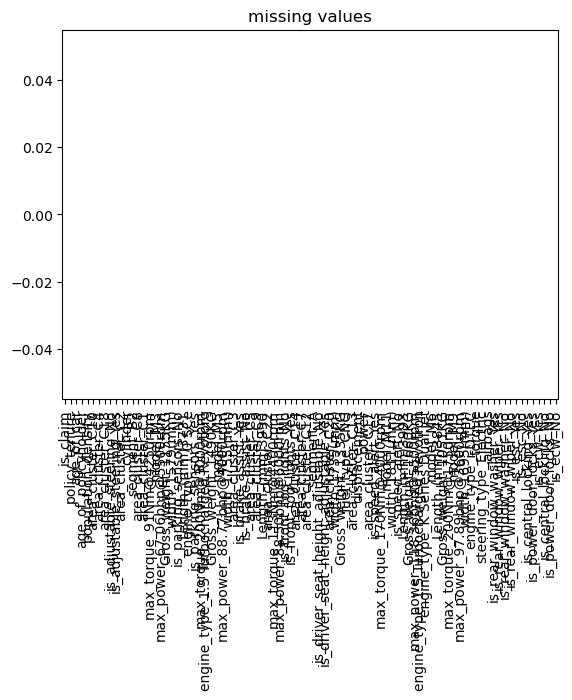

In [10]:
df_final.isnull().sum().plot(kind='bar',title='missing values')

In [11]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df_final.select_dtypes(include=['object', 'bool']).columns:
    df_final[col] = le.fit_transform(df_final[col])

print(f"Total Columns Prepared: {len(df_final.columns)}") 

Total Columns Prepared: 88


In [12]:
df_final.describe()

,is_claim,policy_tenure,age_of_car,age_of_policyholder,population_density,area_cluster_C10,area_cluster_C4,area_cluster_C18,is_adjustable_steering_No,is_adjustable_steering_Yes,...,is_rear_window_washer_No,is_rear_window_wiper_No,is_esc_Yes,is_esc_No,is_central_locking_Yes,is_power_door_locks_Yes,is_ecw_Yes,is_central_locking_No,is_power_door_locks_No,is_ecw_No
count,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.00000,30100.000000,30100.000000,...,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000,30100.000000
mean,0.064086,0.612097,0.069436,0.469028,18882.117342,0.054950,0.011462,0.00392,0.394884,0.605116,...,0.714153,0.714153,0.310498,0.689502,0.723522,0.723522,0.723522,0.276478,0.276478,0.276478
std,0.244911,0.414670,0.056833,0.122673,17737.026405,0.227887,0.106446,0.06249,0.488834,0.488834,...,0.451824,0.451824,0.462705,0.462705,0.447264,0.447264,0.447264,0.447264,0.447264,0.447264
min,0.000000,0.002739,0.000000,0.288462,290.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.207099,0.020000,0.365385,6112.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.575252,0.060000,0.451923,8794.000000,0.000000,0.000000,0.00000,0.000000,1.000000,...,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,0.000000,1.040013,0.110000,0.548077,27003.000000,0.000000,0.000000,0.00000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.376478,1.000000,0.971154,73430.000000,1.000000,1.000000,1.00000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [13]:
print(df_final.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30100 entries, 0 to 30099
Data columns (total 88 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   is_claim                               30100 non-null  int64  
 1   policy_tenure                          30100 non-null  float64
 2   age_of_car                             30100 non-null  float64
 3   age_of_policyholder                    30100 non-null  float64
 4   population_density                     30100 non-null  int64  
 5   area_cluster_C10                       30100 non-null  int64  
 6   area_cluster_C4                        30100 non-null  int64  
 7   area_cluster_C18                       30100 non-null  int64  
 8   is_adjustable_steering_No              30100 non-null  int64  
 9   is_adjustable_steering_Yes             30100 non-null  int64  
 10  area_cluster_C2                        30100 non-null  int64  
 11  cy

In [14]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [15]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
x = df_final.drop('is_claim', axis=1)
y = df_final['is_claim']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# APPLY SCALING
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


<Axes: >

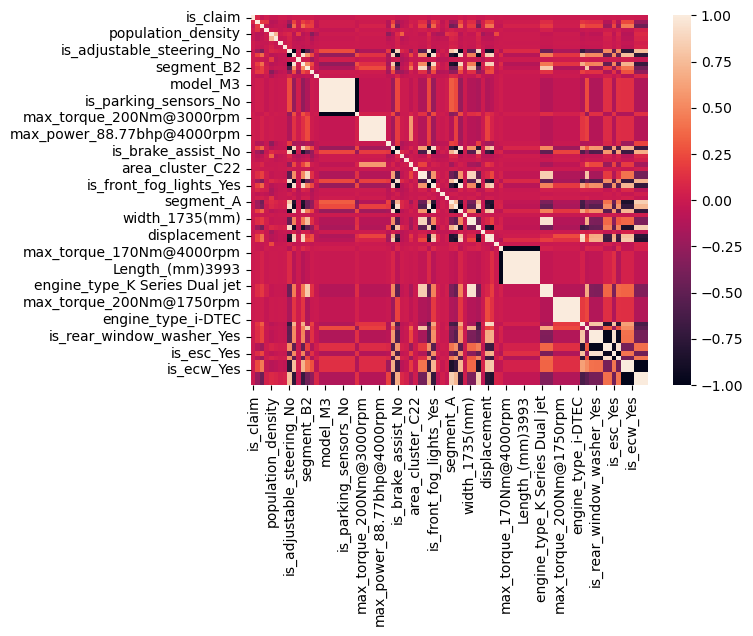

In [18]:
sns.heatmap(df_final.corr())

In [17]:
from sklearn.linear_model import LogisticRegressionCV
model101 = LogisticRegressionCV(class_weight='balanced', max_iter=1000, cv=5)
model101.fit(x_train, y_train)

LogisticRegressionCV(class_weight='balanced', cv=5, max_iter=1000)

In [19]:
model101.score(x,y)

0.5697674418604651

In [20]:
from sklearn.neighbors import KNeighborsClassifier
model102=KNeighborsClassifier(n_neighbors=100)

In [21]:
model102.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=100)

In [22]:
model102.score(x,y)

0.9359136212624585

In [23]:
from sklearn.svm import SVC
model103= SVC(C=2,kernel='rbf')

In [24]:
model103.fit(x_train, y_train)

SVC(C=2)

In [25]:
model103.score(x,y)

0.9359136212624585

In [26]:
from sklearn.tree import DecisionTreeClassifier
model104=DecisionTreeClassifier()
model104.fit(x_train,y_train)

DecisionTreeClassifier()

In [27]:
model104.score(x,y)

0.9733887043189369

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred101 = model101.predict(x_test)
y_true101 = y_test

accuracy101 = accuracy_score(y_true101, y_pred101)
precision101 = precision_score(y_true101, y_pred101, average='macro')
recall101 = recall_score(y_true101, y_pred101, average='macro')
f1101 = f1_score(y_true101, y_pred101, average='macro')

print(f"accuracy = {accuracy101:.2f}")
print(f"precision = {precision101:.2f}")
print(f"recall = {recall101:.2f}")
print(f"f1 = {f1101:.2f}")

accuracy = 0.57
precision = 0.52
recall = 0.56
f1 = 0.43


In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred102 = model102.predict(x_test)
y_true102 = y_test

accuracy102 = accuracy_score(y_true102, y_pred102)
precision102 = precision_score(y_true102, y_pred102, average='macro')
recall102 = recall_score(y_true102, y_pred102, average='macro')
f1102 = f1_score(y_true102, y_pred102, average='macro')

print(f"accuracy = {accuracy102:.2f}")
print(f"precision = {precision102:.2f}")
print(f"recall = {recall102:.2f}")
print(f"f1 = {f1102:.2f}")

accuracy = 0.93
precision = 0.47
recall = 0.50
f1 = 0.48


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred103 = model103.predict(x_test)
y_true103= y_test

accuracy103= accuracy_score(y_true103, y_pred103)
precision103 = precision_score(y_true103, y_pred103, average='macro')
recall103 = recall_score(y_true103, y_pred103, average='macro')
f1103 = f1_score(y_true103, y_pred103, average='macro')

print(f"accuracy = {accuracy103:.2f}")
print(f"precision = {precision103:.2f}")
print(f"recall = {recall103:.2f}")
print(f"f1 = {f1103:.2f}")

accuracy = 0.93
precision = 0.47
recall = 0.50
f1 = 0.48


In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred104= model104.predict(x_test)
y_true104 = y_test

accuracy104 = accuracy_score(y_true104, y_pred104)
precision104 = precision_score(y_true104, y_pred104, average='macro')
recall104 = recall_score(y_true104, y_pred104, average='macro')
f1104 = f1_score(y_true104, y_pred104, average='macro')

print(f"accuracy = {accuracy104:.2f}")
print(f"precision = {precision104:.2f}")
print(f"recall = {recall104:.2f}")
print(f"f1 = {f1104:.2f}")

accuracy = 0.87
precision = 0.50
recall = 0.50
f1 = 0.50
